In [13]:
%load_ext autoreload
%autoreload 2
import pandas as pd
import numpy as np
from vae_training import Modeltraining
from data_prep import DataPrep
from portfolio_eval import PriceData, PortfolioSelection, DiversificationAnalysis
from reconstruction_eval import ReconstructionEval, ImputationEval
import optuna
import gc
import torch
import json
from torch.utils.data import TensorDataset, DataLoader

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
data = DataPrep.full_data_prep(0.7, 0.15, 0.15, '2023-12-31', 1)
X_train_scaled = data['train']
X_train_mask = data['train_mask']
X_val_scaled = data['val']
X_val_mask = data['val_mask']
X_test_scaled = data['test']
X_test_mask = data['test_mask']
test_entities = data['test_entities']
val_entities = data['val_entities']
usable_features = data['usable_features']
scaler = data['scaler']

Train Rows: 11219 (5548 Firmen)
Val Rows:   1181 (1189 Firmen)
Test Rows:  1186 (1190 Firmen)


In [3]:
X_full_scaled = np.concatenate([X_train_scaled, X_val_scaled], axis=0)
X_full_mask = np.concatenate([X_train_mask, X_val_mask], axis=0)

### GridSearch zur Bestimmung idealer Parameter auf Validierungsmenge

In [4]:
returns = PriceData.execute(val_entities, '2024-01-01', '2026-09-30', 0.00)

$LBRDK: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30)
$MLEFA.PA: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30) (Yahoo error = "No data found, symbol may be delisted")
$SNSE: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30) (Yahoo error = "No data found, symbol may be delisted")
$1246.HK: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30) (Yahoo error = "No data found, symbol may be delisted")
$MLVRF.PA: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30)
$BRM.MI: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30) (Yahoo error = "No data found, symbol may be delisted")
$PRA: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30) (Yahoo error = "No data found, symbol may be delisted")
$ALBT: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30) (Yahoo error = "No data found, symbol may be delisted")
$EIFF.PA: possibly delisted; no pri

Eingangs-Ticker:          1181
Nutzbare Ticker nach 0.0 Filterung: 1062


In [100]:
from optuna.samplers import TPESampler

# Sampler mit gewünschter Anzahl an Random Trials (z. B. 20) definieren
sampler = TPESampler(n_startup_trials=50, seed=42)
STUDY_NAME = "k-means_euc_only_final2" 
# Festgelegte Konstanten
num_assets = [10, 30, 50]
epochs = 200
device = "cuda"
print_every = None
eval_every = None
seeds_for_training = [1, 2, 3] 

HIDDEN_DIMS = {
    "256-128": (256, 128),
    "128": (128,),
    "128-64": (128, 64),
    "64-32": (64, 32),
    "512-256": (512, 256),
    "512-256-128": (512, 256, 128),
    "1024-512-256-128": (1024, 512, 256, 128),
    "1024-256-128": (1024, 256, 128),
    "1024-512-256-128-64": (1024, 512, 256, 128, 64),
    "2048-1024-512-256-128-64": (2048, 1024, 512, 256, 128, 64),
    "2048-512-128-": (2048, 512, 128),
}

def set_seed(s):
    np.random.seed(s)
    torch.manual_seed(s) 
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

def objective(trial):
    # 1. Learning & Regularisierung
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    dropout_rate = trial.suggest_float("dropout_rate", 0.0, 0.5, step=0.05)
    batch_size = trial.suggest_categorical("batch_size", [128, 256])

    # 2. Architektur & Dimensionen
    latent_dim = trial.suggest_categorical("latent_dim", [4, 8, 16, 32, 64])
    emb_dim = trial.suggest_categorical("emb_dim", [1, 2, 4, 8, 16])
    hidden_key = trial.suggest_categorical("hidden_dims", list(HIDDEN_DIMS.keys()))
    hidden_dims = HIDDEN_DIMS[hidden_key]
    activation = trial.suggest_categorical("activation", ["elu", "gelu", "leaky_relu", "silu"])

    # 3. VAE-spezifische Loss-Hyperparameter
    beta = trial.suggest_float("beta", 1e-4, 1.5, log=True)
    free_bits = trial.suggest_float("free_bits", 0.0, 1.0, step=0.1)
    kl_warmup_epochs = trial.suggest_int("kl_warmup_epochs", 0, 70, step=10)

    if hidden_dims[-1] < latent_dim:
        raise optuna.TrialPruned("Bottleneck kleiner als latent_dim.")

    dr_results = {('kmeans', N): [] for N in num_assets}
    best_epochs = []    

    # SCHLEIFE ÜBER ALLE TRAINING-SEEDS
    for ts in seeds_for_training:
        set_seed(ts)
        model = None
        try:
            model, finale_metrics, history = Modeltraining.train_vae(
                X_train_scaled, X_train_mask, X_val_scaled, X_val_mask,
                emb_dim=emb_dim,
                hidden_dims=hidden_dims,
                latent_dim=latent_dim,
                dropout_rate=dropout_rate,
                batch_size=batch_size,
                lr=lr,
                epochs=epochs,
                beta=beta,
                device=device,
                activation_fun=activation,
                print_every=print_every,
                eval_every=eval_every,
                feature_names=usable_features,
                kl_warmup_epochs=kl_warmup_epochs,
                free_bits=free_bits,
                scaler=scaler,
                early_stopping_patience=25,
            )
            best_epochs.append(finale_metrics["best_epoch"])
            latent_mu = Modeltraining.get_latent_embeddings(model, X_val_scaled, X_val_mask, device=device)

            for N in num_assets:
                # Deterministisch: einmal pro Trainingsseed, keine Clustering-Seeds nötig
                kmeans_euc_pf = PortfolioSelection.select_cluster_diverse_portfolio(latent_mu, val_entities, returns.columns, n_assets=N, use_cosine=False, random_state=ts,)   # Wert irrelevant, falls wirklich deterministisch
                dr_results[("kmeans", N)].append(DiversificationAnalysis.diversification_ratio(returns, kmeans_euc_pf)['diversification_ratio'])

        finally:
            # GPU-Speicher nach jedem einzelnen Modelltraining aufräumen
            if model is not None:
                del model
            gc.collect()
            torch.cuda.empty_cache()
    
    # Aggregation nach der Seed-Schleife:
    for (m, N), vals in dr_results.items():
        vals = np.array(vals)
        if not np.all(np.isfinite(vals)):
            raise optuna.TrialPruned(f"Nicht-finite DR ({m}, N={N})")
        trial.set_user_attr(f"DR_kmeans_N={N}_mean", float(vals.mean()))
        trial.set_user_attr(f"DR_kmeans_N={N}_std", float(vals.std(ddof=1)))
        trial.set_user_attr(f"DR_kmeans_N={N}_per_seed", vals.tolist())
        trial.set_user_attr("best_epochs", best_epochs)
    return float(np.mean(dr_results[("kmeans", 30)]))



# Study anlegen
study = optuna.create_study(
    direction="maximize",
    sampler=sampler,
    pruner=optuna.pruners.NopPruner(),
    study_name=STUDY_NAME,
    storage=f"sqlite:///{STUDY_NAME}.db",
    load_if_exists=True,
)

study.optimize(objective, n_trials=100, gc_after_trial=True,)

best_trial = study.best_trial
ua = best_trial.user_attrs

print(f"Study: {STUDY_NAME} | Bester Trial: #{best_trial.number}")
print(f"Zielwert (Optuna): {best_trial.value:.4f}  [Agglo, N=30]")
print(f"Beste Parameter: {best_trial.params}")
print(f"Best Epochs je Trainingsseed {seeds_for_training}: {ua['best_epochs']}\n")

header = f"{'N':>3} | {'Metrik':<10} | {'Mean DR':>8} | {'Std (Trainingsseeds)':>20} | Einzelwerte je Trainingsseed"
print(header)
print("-" * len(header))
for N in num_assets:
    mean = ua[f"DR_kmeans_N={N}_mean"]
    std = ua[f"DR_kmeans_N={N}_std"]
    per_seed = [round(v, 3) for v in ua[f"DR_kmeans_N={N}_per_seed"]]
    print(f"{N:>3} | {'k-Means':<10} | {mean:8.4f} | {std:20.4f} | {per_seed}")
    print()

# Optional: alle Trials sichern
study.trials_dataframe().to_csv(f"{STUDY_NAME}_all_trials.csv", index=False)

[I 2026-10-07 22:15:22,384] A new study created in RDB with name: k-means_euc_only_final2
[I 2026-10-07 22:23:10,067] Trial 0 finished with value: 3.3354339314107073 and parameters: {'lr': 0.0005611516415334506, 'dropout_rate': 0.5, 'batch_size': 128, 'latent_dim': 32, 'emb_dim': 4, 'hidden_dims': '1024-512-256-128', 'activation': 'elu', 'beta': 0.00015630798428079148, 'free_bits': 0.6000000000000001, 'kl_warmup_epochs': 10}. Best is trial 0 with value: 3.3354339314107073.
[I 2026-10-07 22:29:01,974] Trial 1 finished with value: 3.288090467627043 and parameters: {'lr': 0.00013492834268013249, 'dropout_rate': 0.5, 'batch_size': 128, 'latent_dim': 16, 'emb_dim': 4, 'hidden_dims': '512-256', 'activation': 'silu', 'beta': 0.0013588712796919799, 'free_bits': 0.9, 'kl_warmup_epochs': 20}. Best is trial 0 with value: 3.3354339314107073.
[I 2026-10-07 22:32:56,544] Trial 2 finished with value: 3.55153939801052 and parameters: {'lr': 0.0003646439558980723, 'dropout_rate': 0.25, 'batch_size': 25


Early Stopping bei Epoche 123: seit 25 Epochen keine Verbesserung in val_loss (bestes Ergebnis: 1.5224 bei Epoche 98).

Early Stopping bei Epoche 144: seit 25 Epochen keine Verbesserung in val_loss (bestes Ergebnis: 1.5087 bei Epoche 119).

Early Stopping bei Epoche 116: seit 25 Epochen keine Verbesserung in val_loss (bestes Ergebnis: 1.5346 bei Epoche 91).


[I 2026-10-07 22:41:54,774] Trial 4 finished with value: 3.290088155929286 and parameters: {'lr': 0.00010325337616482048, 'dropout_rate': 0.25, 'batch_size': 128, 'latent_dim': 16, 'emb_dim': 4, 'hidden_dims': '1024-512-256-128-64', 'activation': 'gelu', 'beta': 0.15156293903048174, 'free_bits': 0.2, 'kl_warmup_epochs': 50}. Best is trial 2 with value: 3.55153939801052.
[I 2026-10-07 22:47:21,079] Trial 5 finished with value: 2.7708811335490933 and parameters: {'lr': 0.0005439591236568526, 'dropout_rate': 0.30000000000000004, 'batch_size': 128, 'latent_dim': 8, 'emb_dim': 2, 'hidden_dims': '512-256', 'activation': 'gelu', 'beta': 0.001023286484452246, 'free_bits': 0.1, 'kl_warmup_epochs': 70}. Best is trial 2 with value: 3.55153939801052.



Early Stopping bei Epoche 161: seit 25 Epochen keine Verbesserung in val_loss (bestes Ergebnis: 0.8331 bei Epoche 136).


[I 2026-10-07 22:51:42,446] Trial 6 finished with value: 3.2792688928382154 and parameters: {'lr': 0.006321732490144022, 'dropout_rate': 0.30000000000000004, 'batch_size': 256, 'latent_dim': 8, 'emb_dim': 4, 'hidden_dims': '1024-512-256-128-64', 'activation': 'leaky_relu', 'beta': 0.02362156082736895, 'free_bits': 0.1, 'kl_warmup_epochs': 20}. Best is trial 2 with value: 3.55153939801052.
[I 2026-10-07 23:00:54,743] Trial 7 finished with value: 3.2117500046598306 and parameters: {'lr': 0.0003391600849438615, 'dropout_rate': 0.1, 'batch_size': 128, 'latent_dim': 4, 'emb_dim': 4, 'hidden_dims': '2048-1024-512-256-128-64', 'activation': 'elu', 'beta': 0.002106178695858201, 'free_bits': 0.1, 'kl_warmup_epochs': 40}. Best is trial 2 with value: 3.55153939801052.



Early Stopping bei Epoche 149: seit 25 Epochen keine Verbesserung in val_loss (bestes Ergebnis: 0.6111 bei Epoche 124).


... (74 outputs left out)

[I 2026-10-08 06:01:21,707] Trial 98 finished with value: 3.557481607921238 and parameters: {'lr': 0.00023248669142210646, 'dropout_rate': 0.05, 'batch_size': 128, 'latent_dim': 4, 'emb_dim': 4, 'hidden_dims': '1024-512-256-128', 'activation': 'silu', 'beta': 0.009262274831805656, 'free_bits': 0.4, 'kl_warmup_epochs': 30}. Best is trial 84 with value: 3.7027482512881282.



Early Stopping bei Epoche 124: seit 25 Epochen keine Verbesserung in val_loss (bestes Ergebnis: 0.6094 bei Epoche 99).

Early Stopping bei Epoche 85: seit 25 Epochen keine Verbesserung in val_loss (bestes Ergebnis: 0.6018 bei Epoche 60).

Early Stopping bei Epoche 93: seit 25 Epochen keine Verbesserung in val_loss (bestes Ergebnis: 0.6039 bei Epoche 68).


[I 2026-10-08 06:05:58,403] Trial 99 finished with value: 3.5047824947177797 and parameters: {'lr': 0.00016563509528558725, 'dropout_rate': 0.0, 'batch_size': 128, 'latent_dim': 4, 'emb_dim': 4, 'hidden_dims': '2048-1024-512-256-128-64', 'activation': 'silu', 'beta': 0.014377645066697543, 'free_bits': 0.5, 'kl_warmup_epochs': 20}. Best is trial 84 with value: 3.7027482512881282.


Study: k-means_euc_only_final2 | Bester Trial: #84
Zielwert (Optuna): 3.7027  [Agglo, N=30]
Beste Parameter: {'lr': 0.00043585216199533606, 'dropout_rate': 0.0, 'batch_size': 128, 'latent_dim': 4, 'emb_dim': 4, 'hidden_dims': '128', 'activation': 'silu', 'beta': 0.026870900785618834, 'free_bits': 0.30000000000000004, 'kl_warmup_epochs': 30}
Best Epochs je Trainingsseed [1, 2, 3]: [199, 198, 199]

  N | Metrik     |  Mean DR | Std (Trainingsseeds) | Einzelwerte je Trainingsseed
---------------------------------------------------------------------------------
 10 | k-Means    |   2.3747 |               0.1036 | [2.256, 2.42, 2.448]

 30 | k-Means    |   3.7027 |               0.1863 | [3.585, 3.918, 3.605]

 50 | k-Means    |   3.7853 |               0.1523 | [3.894, 3.85, 3.611]



In [22]:
num_assets = [10, 30, 50]
for n in num_assets:
    erg_rand = []
    for i in range(10000):
        random_portfolio = PortfolioSelection.random_portfolio(n, returns)
        random_ergebnis = DiversificationAnalysis.diversification_ratio(returns, random_portfolio)
        erg_rand.append(random_ergebnis['diversification_ratio'])
    print(f'Ergebnis Random Portfolio mit {n} = {np.mean(erg_rand)}')

Ergebnis Random Portfolio mit 10 = 2.2870124552427633
Ergebnis Random Portfolio mit 30 = 3.087340993266154
Ergebnis Random Portfolio mit 50 = 3.3792939458919813


### Finale Evaluation auf der Testmenge

In [8]:
returns_test = PriceData.execute(test_entities, '2024-01-01', '2026-09-30', 0.00)

$NFBK: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30)
$CMU: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30) (Yahoo error = "No data found, symbol may be delisted")
$ALVG.PA: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30) (Yahoo error = "No data found, symbol may be delisted")
$HLX: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30)
$TALK: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30)
$MLMAC.LS: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30)
$ELIMP.OL: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30)
$MVE.OL: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30)
$MLCAN.PA: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30)
$EA: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30)
$STAR7.MI: possibly delisted; no price data found  (1d 2024-01-01 -> 2026-09-30)
$MLAST.PA: possibly deli

Eingangs-Ticker:          1186
Nutzbare Ticker nach 0.0 Filterung: 1065


In [23]:
num_assets = [10, 30, 50]
for n in num_assets:
    erg_rand = []
    for i in range(10000):
        random_portfolio = PortfolioSelection.random_portfolio(n, returns_test)
        random_ergebnis = DiversificationAnalysis.diversification_ratio(returns_test, random_portfolio)
        erg_rand.append(random_ergebnis['diversification_ratio'])
    print(f'Ergebnis Random Portfolio mit {n} = {np.mean(erg_rand)}')

Ergebnis Random Portfolio mit 10 = 2.2969329931471205
Ergebnis Random Portfolio mit 30 = 3.1929195729441737
Ergebnis Random Portfolio mit 50 = 3.582331248661183


In [33]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics.pairwise import cosine_distances

train_seeds = [ i for i in range(100)] # 

# Hilfsfunktion zum sauberen Fixieren aller Random-Seeds
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    
# Hyperparameter nach der auf SIM konzentrierten Optuna Suche
lr = 0.0004891851956277684
dropout_rate = 0.5
batch_size = 256
latent_dim = 8
emb_dim = 4
hidden_dims = (64, 32)
activation = 'leaky_relu'
beta = 1.1657593911792454
free_bits = 0.6000000000000001
kl_warmup_epochs = 60
epochs = int(np.mean([163, 152, 199]))
device = "cuda"
print_every = 10
eval_every = 10

# Speicher für die Endergebnisse über alle Trainings-Runs hinweg:
# Format: {10: {'sim': [], 'euc': []}, 30: ..., 50: ...}
results = {10: [], 30: [], 50: []}
portfolios = {10: [], 30: [], 50: []}

print(f"=== Starte Training über {len(train_seeds)} Modell-Seeds ===")

for run_idx, seed in enumerate(train_seeds, 1):
    print(f"\n--- Model-Run {run_idx}/{len(train_seeds)} (Seed: {seed}) ---")
    set_seed(seed)
    
    # 1. VAE mit dem aktuellen Seed trainieren
    model, finale_metrics, history = Modeltraining.train_vae(
        X_full_scaled, X_full_mask, X_val_scaled, X_val_mask, 
        emb_dim=emb_dim, hidden_dims=hidden_dims, latent_dim=latent_dim, dropout_rate=dropout_rate,
        batch_size=batch_size, lr=lr, epochs=epochs, beta=beta, activation_fun=activation, device=device, 
        print_every=print_every, eval_every=eval_every, feature_names=usable_features, 
        kl_warmup_epochs=kl_warmup_epochs, free_bits=free_bits, scaler=scaler, early_stopping_patience=169
    )

    # 2. Latent Embeddings für Testmenge extrahieren
    latent_mu = Modeltraining.get_latent_embeddings(model, X_test_scaled, X_test_mask, device=device)

    # 3. Portfolios evaluieren
    for asset in [10, 30, 50]:
        pf_agglo_euc = PortfolioSelection.select_agglomerative_diverse_portfolio(
            latent_mu, test_entities, returns_test.columns, asset, random_state=i, use_cosine=False)
        div = DiversificationAnalysis.diversification_ratio(returns_test, pf_agglo_euc)
        results[asset].append(div['diversification_ratio'])
        portfolios[asset].append(div)

        print(f"Run {run_idx} | Assets {asset} ->  Agglo Euc Mean: {div['diversification_ratio']} ")

for n, res in results.items():
    print(f'N={n} Mean Diversification Ratio = {np.mean(res)} Std Diversification Ratio = {np.std(res, ddof=1)}')


=== Starte Training über 100 Modell-Seeds ===

--- Model-Run 1/100 (Seed: 0) ---
Epoch   1 | train: loss=2.2335 recon=2.1310 kl=5.2777 | val: loss=2.0140 recon=1.9205 kl=4.8121 val_rel_err=153.28%
Epoch  10 | train: loss=2.4944 recon=1.5314 kl=4.9565 | val: loss=2.3649 recon=1.4288 kl=4.8175 val_rel_err=148.68%
Epoch  20 | train: loss=3.3406 recon=1.4452 kl=4.8776 | val: loss=3.2390 recon=1.3736 kl=4.8003 val_rel_err=151.37%
Epoch  30 | train: loss=4.2485 recon=1.4240 kl=4.8458 | val: loss=4.1170 recon=1.3192 kl=4.8000 val_rel_err=152.87%
Epoch  40 | train: loss=5.1541 recon=1.3996 kl=4.8309 | val: loss=5.0331 recon=1.3026 kl=4.8000 val_rel_err=153.60%
Epoch  50 | train: loss=6.0742 recon=1.3899 kl=4.8219 | val: loss=5.9512 recon=1.2882 kl=4.8000 val_rel_err=152.65%
Epoch  60 | train: loss=6.9844 recon=1.3700 kl=4.8160 | val: loss=6.8726 recon=1.2770 kl=4.8000 val_rel_err=152.15%
Epoch  70 | train: loss=6.9751 recon=1.3612 kl=4.8157 | val: loss=6.8647 recon=1.2691 kl=4.8000 val_rel_err

In [35]:
for n, res in results.items():
    print(f'{N}={np.median(res)}')

50=2.279427013187574
50=3.347317213070846
50=3.7922926962520025


In [14]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics.pairwise import cosine_distances

train_seeds = [ i for i in range(100)] # 
{'lr': 0.001666473454836989, 'dropout_rate': 0.1, 'batch_size': 256, 'latent_dim': 64, 'emb_dim': 8, 'hidden_dims': '2048-1024-512-256-128-64', 'activation': 'leaky_relu', 'beta': 0.05597595564421984, 'free_bits': 0.7000000000000001, 'kl_warmup_epochs': 60}
# Hilfsfunktion zum sauberen Fixieren aller Random-Seeds
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
# Hyperparameter nach der auf SIM konzentrierten Optuna Suche
lr = 0.001666473454836989
dropout_rate = 0.1
batch_size = 256
latent_dim = 64
emb_dim = 8
hidden_dims = (2048, 1024, 512, 256, 128, 64)
activation = 'leaky_relu'
beta = 0.05597595564421984
free_bits = 0.7000000000000001
kl_warmup_epochs = 60
epochs = int(np.mean([198, 148, 197]))
device = "cuda"
print_every = 10
eval_every = 10

# Speicher für die Endergebnisse über alle Trainings-Runs hinweg:
# Format: {10: {'sim': [], 'euc': []}, 30: ..., 50: ...}
results_kmeans = {10: [], 30: [], 50: []}
portfolios_kmeans = {10: [], 30: [], 50: []}
mse = []
mae = []
rel_error = []
per_feat_mse = []
per_feat_mae = []
implementation_mse = []
implementation_mae = []
kl_dims = []
print(f"=== Starte Training über {len(train_seeds)} Modell-Seeds ===")

for run_idx, seed in enumerate(train_seeds, 1):
    print(f"\n--- Model-Run {run_idx}/{len(train_seeds)} (Seed: {seed}) ---")
    set_seed(seed)
    
    # 1. VAE mit dem aktuellen Seed trainieren
    model, finale_metrics, history = Modeltraining.train_vae(
        X_full_scaled, X_full_mask, X_val_scaled, X_val_mask, 
        emb_dim=emb_dim, hidden_dims=hidden_dims, latent_dim=latent_dim, dropout_rate=dropout_rate,
        batch_size=batch_size, lr=lr, epochs=epochs, beta=beta, activation_fun=activation, device=device, 
        print_every=print_every, eval_every=eval_every, feature_names=usable_features, 
        kl_warmup_epochs=kl_warmup_epochs, free_bits=free_bits, scaler=scaler, early_stopping_patience=169
    )

    # 2. Latent Embeddings für Testmenge extrahieren
    latent_mu = Modeltraining.get_latent_embeddings(model, X_test_scaled, X_test_mask, device=device)
    reconstruction = ReconstructionEval.evaluate_reconstruction(model, X_test_scaled,X_test_mask, device=device)
    imp_mse, imp_mae, imp_nmae_std, true_vals, pred_vals = ImputationEval.evaluate_imputation_quality(model,X_test_scaled, X_test_mask, device=device)
    x_hat = reconstruction['x_hat']
    #relative_error = ReconstructionEval.relative_error(X_test_scaled, x_hat, X_test_mask, scaler)
    #mean_relative_error = relative_error.sum() / X_test_mask.sum().clamp(min=1)
    #rel_error.append(mean_relative_error)
    mse.append(reconstruction['overall_mse'])
    mae.append(reconstruction['overall_mae'])
    per_feat_mse.append(reconstruction['per_feature_mse'])
    per_feat_mae.append(reconstruction['per_feature_mae'])
    implementation_mse.append(imp_mse)
    implementation_mae.append(imp_mae)
    X_t = torch.as_tensor(X_test_scaled, dtype=torch.float32)
    m_t = torch.as_tensor(X_test_mask, dtype=torch.float32)   # Maske: 1 = beobachtet, 0 = fehlend

    dataset = TensorDataset(X_t, m_t)
    loader = DataLoader(
        dataset,
        batch_size=256,
        shuffle=False,      # für die Analyse egal, shuffle wird nur im Training gebraucht
        drop_last=False,
    )
    kl_dim = ReconstructionEval.analyze_kl_per_dimension(model, loader, device)
    kl_dims.append(kl_dim)


    # 3. Portfolios evaluieren
    for asset in [10, 30, 50]:
        pf_kmeans_euc = PortfolioSelection.select_cluster_diverse_portfolio(latent_mu, test_entities, returns_test.columns,asset, random_state=seed, use_cosine=False)
        div = DiversificationAnalysis.diversification_ratio(returns_test, pf_kmeans_euc)
        results_kmeans[asset].append(div['diversification_ratio'])
        portfolios_kmeans[asset].append(div)

        print(f"Run {run_idx} | Assets {asset} ->  k-Means Euc Mean: {div['diversification_ratio']} ")
    print(f'Current N=30 Mean = {np.mean(results_kmeans[30])} Current N=30 Median = {np.median(results_kmeans[30])}')

for n, res in results_kmeans.items():
    print(f'N={n} Mean Diversification Ratio = {np.mean(res)} Std Diversification Ratio = {np.std(res, ddof=1)}')


=== Starte Training über 100 Modell-Seeds ===

--- Model-Run 1/100 (Seed: 0) ---
Epoch   1 | train: loss=1.3158 recon=1.2607 kl=58.9876 | val: loss=1.0323 recon=0.9633 kl=73.9463 val_rel_err=146.35%
Epoch  10 | train: loss=1.1227 recon=0.6890 kl=46.4961 | val: loss=1.0557 recon=0.6241 kl=46.2536 val_rel_err=137.92%
Epoch  20 | train: loss=1.4776 recon=0.6308 kl=45.3833 | val: loss=1.4334 recon=0.5927 kl=45.0560 val_rel_err=133.68%
Epoch  30 | train: loss=1.8757 recon=0.6126 kl=45.1303 | val: loss=1.8096 recon=0.5529 kl=44.9039 val_rel_err=134.13%
Epoch  40 | train: loss=2.2697 recon=0.5899 kl=45.0139 | val: loss=2.2112 recon=0.5374 kl=44.8538 val_rel_err=132.80%
Epoch  50 | train: loss=2.6691 recon=0.5721 kl=44.9549 | val: loss=2.6085 recon=0.5176 kl=44.8255 val_rel_err=132.31%
Epoch  60 | train: loss=3.0797 recon=0.5654 kl=44.9185 | val: loss=3.0224 recon=0.5137 kl=44.8173 val_rel_err=132.67%
Epoch  70 | train: loss=3.0643 recon=0.5504 kl=44.9088 | val: loss=3.0139 recon=0.5052 kl=44.

In [ ]:
for n, res in results_kmeans.items():
    print(f'{n}={np.median(res)}')

10=2.34935662573463
30=3.2969672106068684
50=3.7128943166410826


In [17]:
print(np.array(results_kmeans[30]).min())
print(np.array(results_kmeans[30]).max())

2.7188524601120143
3.9099078271113346


Berechne t-SNE Projektion...


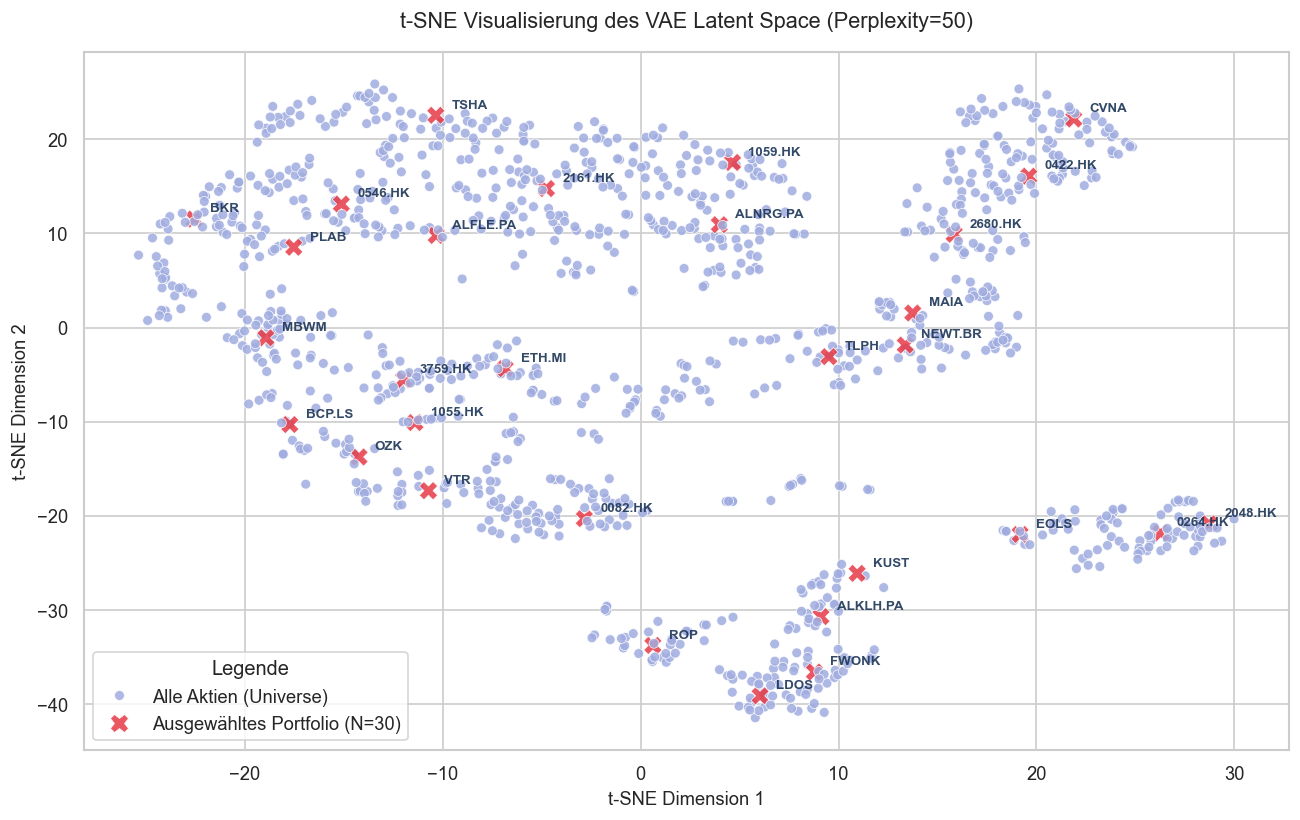

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.manifold import TSNE


def plot_tsne_latent_space(
    embeddings: np.ndarray,
    entity_codes: list,
    selected_portfolio_tickers: list = None,
    perplexity: int = 30,
    random_state: int = 42,
):
    """Erstellt einen 2D t-SNE Scatterplot der Latent Embeddings.

    Parameters:
    -----------
    embeddings : np.ndarray
        Die VAE Latent Embeddings (Shape: N_samples x Latent_Dim)
    entity_codes : list
        Liste der zugehörigen Ticker / EntityCodes
    selected_portfolio_tickers : list, optional
        Liste von Tickern (z.B. deine 30 VAE-Aktien), die im Plot hervorgehoben
        werden sollen
    perplexity : int, default 30
        t-SNE Parameter (typisch zwischen 5 und 50, bestimmt die Berücksichtigung
        lokaler vs. globaler Strukturen)
    random_state : int, default 42
        Seed für Reproduzierbarkeit
    """
    print("Berechne t-SNE Projektion...")
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=random_state,
        init="pca",
        learning_rate="auto",
    )
    embeddings_2d = tsne.fit_transform(embeddings)

    # DataFrame für einfaches Plotten erstellen
    df_tsne = pd.DataFrame(
        {
            "TSNE_1": embeddings_2d[:, 0],
            "TSNE_2": embeddings_2d[:, 1],
            "Ticker": entity_codes,
            "Type": "Alle Aktien (Universe)",
        }
    )

    # Falls ein ausgewähltes Portfolio übergeben wurde, diese Aktien markieren
    if selected_portfolio_tickers is not None:
        selected_set = set(selected_portfolio_tickers)
        df_tsne.loc[df_tsne["Ticker"].isin(selected_set), "Type"] = (
            "Ausgewähltes Portfolio (N=30)"
        )

    # Styling & Visualisierung
    plt.figure(figsize=(11, 7), dpi=120)
    sns.set_theme(style="whitegrid")

    # Scatterplot zeichnen
    ax = sns.scatterplot(
        data=df_tsne,
        x="TSNE_1",
        y="TSNE_2",
        hue="Type",
        style="Type",
        palette={
            "Alle Aktien (Universe)": "#A0ACE0",
            "Ausgewähltes Portfolio (N=30)": "#E63946",
        },
        markers={
            "Alle Aktien (Universe)": "o",
            "Ausgewähltes Portfolio (N=30)": "X",
        },
        size="Type",
        sizes={
            "Alle Aktien (Universe)": 35,
            "Ausgewähltes Portfolio (N=30)": 120,
        },
        alpha=0.85,
    )

    # Optional: Ticker-Namen für die ausgewählten Portfolio-Aktien anzeigen
    if selected_portfolio_tickers is not None:
        df_selected = df_tsne[
            df_tsne["Type"] == "Ausgewähltes Portfolio (N=30)"
        ]
        for _, row in df_selected.iterrows():
            ax.text(
                row["TSNE_1"] + 0.8,
                row["TSNE_2"] + 0.8,
                row["Ticker"],
                fontsize=8,
                weight="bold",
                color="#1D3557",
                alpha=0.9,
            )

    plt.title(
        f"t-SNE Visualisierung des VAE Latent Space (Perplexity={perplexity})",
        fontsize=13,
        pad=15,
    )
    plt.xlabel("t-SNE Dimension 1", fontsize=11)
    plt.ylabel("t-SNE Dimension 2", fontsize=11)
    plt.legend(title="Legende", loc="best", frameon=True)
    plt.tight_layout()
    plt.show()

latent_mu = Modeltraining.get_latent_embeddings(model, X_test_scaled, X_test_mask, device=device)
pf_kmeans_euc = PortfolioSelection.select_cluster_diverse_portfolio(latent_mu, test_entities, returns_test.columns,30, random_state=seed, use_cosine=False)
div = DiversificationAnalysis.diversification_ratio(returns_test, pf_kmeans_euc)
# --- Aufrufbeispiel ---
# embeddings_test: Deine VAE Latent Vectors
# X_test_EntityCodes: Deine Ticker-Liste
plot_tsne_latent_space(
    embeddings=latent_mu,
    entity_codes=test_entities,
    selected_portfolio_tickers=pf_kmeans_euc,  # Oder vae_kmeans_portfolio
    perplexity=50,
)

In [ ]:
from sklearn.cluster import KMeans
latent_mu = Modeltraining.get_latent_embeddings(model, X_test_scaled, X_test_mask, device=device)
pf_kmeans_euc = PortfolioSelection.select_cluster_diverse_portfolio(latent_mu, test_entities, returns_test.columns,30, random_state=seed, use_cosine=False)
div = DiversificationAnalysis.diversification_ratio(returns_test, pf_kmeans_euc)

embeddings = np.asarray(latent_mu, dtype=float)
emb_df = pd.DataFrame(embeddings, index=list(test_entities))

valid_companies = [c for c in emb_df.index if c in set(returns_test.columns)]
if len(valid_companies) < 30:
    raise ValueError(
        f"Nur {len(valid_companies)} übereinstimmende Unternehmen verfügbar, "
        f"aber {30} angefordert."
    )

sub_emb = emb_df.loc[valid_companies]

if sub_emb.index.duplicated().any():
    raise ValueError("Doppelte EntityCodes in embeddings/entities gefunden.")

X = sub_emb.values
if False:
    norms = np.linalg.norm(X, axis=1, keepdims=True)
    norms[norms == 0] = 1.0  # Nullvektoren defensiv abfangen
    X = X / norms

kmeans = KMeans(n_clusters=30, init='k-means++', random_state=1, n_init=100)
cluster_labels = kmeans.fit_predict(X)
cluster_labels

array([20,  8, 11, ..., 20, 13, 10])

In [77]:
from data_prep import DataPrep
import pandas as pd
import yfinance as yf
from portfolio_eval import PriceData, PortfolioSelection, DiversificationAnalysis
import numpy as np

company_clusters = pd.Series(
    cluster_labels, index=sub_emb.index, name="Cluster"
)
clusters = company_clusters.reset_index()
clusters[clusters['Cluster'] == 1]

data = []

for symbol in test_entities:
    t = yf.Ticker(symbol)
    info = t.info

    data.append(
        {
            "Ticker": symbol,
            "Name": info.get("shortName", "N/A"),
            "Sektor": info.get("sector", "N/A"),
            "Branche": info.get("industry", "N/A"),
            "Land": info.get("country", "N/A"),
        }
    )
df = pd.DataFrame(data)
df

HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: 0431.HK"}}}
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: 0724.HK"}}}
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: ALVG.PA"}}}
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: CMU"}}}
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: DIAD.MI"}}}
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: EVTV"}}}
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: MLAST.PA"}}}
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote 

,Ticker,Name,Sektor,Branche,Land
0,0006.HK,POWER ASSETS,Utilities,Utilities - Independent Power Producers,Hong Kong
1,0008.HK,PCCW,Communication Services,Telecom Services,Hong Kong
2,0026.HK,CHINA MOTOR BUS,Real Estate,Real Estate - Diversified,Hong Kong
3,0027.HK,GALAXY ENT,Consumer Cyclical,Resorts & Casinos,Hong Kong
4,0033.HK,INTL GENIUS,Financial Services,Asset Management,China
...,...,...,...,...,...
1181,ZD,"Ziff Davis, Inc.",Communication Services,Advertising Agencies,United States
1182,ZG,"Zillow Group, Inc.",Communication Services,Internet Content & Information,United States
1183,ZNTL,"Zentalis Pharmaceuticals, Inc.",Healthcare,Biotechnology,United States
1184,ZTEK,Zentek Ltd.,Healthcare,Medical Instruments & Supplies,Canada


In [92]:
df_merged = pd.merge(
    df, clusters, left_on="Ticker", right_on="index", how="left"
)
df_merged

,Ticker,Name,Sektor,Branche,Land,index,Cluster
0,0006.HK,POWER ASSETS,Utilities,Utilities - Independent Power Producers,Hong Kong,0006.HK,20.0
1,0008.HK,PCCW,Communication Services,Telecom Services,Hong Kong,0008.HK,8.0
2,0026.HK,CHINA MOTOR BUS,Real Estate,Real Estate - Diversified,Hong Kong,0026.HK,11.0
3,0027.HK,GALAXY ENT,Consumer Cyclical,Resorts & Casinos,Hong Kong,0027.HK,3.0
4,0033.HK,INTL GENIUS,Financial Services,Asset Management,China,0033.HK,6.0
...,...,...,...,...,...,...,...
1181,ZD,"Ziff Davis, Inc.",Communication Services,Advertising Agencies,United States,ZD,22.0
1182,ZG,"Zillow Group, Inc.",Communication Services,Internet Content & Information,United States,ZG,20.0
1183,ZNTL,"Zentalis Pharmaceuticals, Inc.",Healthcare,Biotechnology,United States,ZNTL,13.0
1184,ZTEK,Zentek Ltd.,Healthcare,Medical Instruments & Supplies,Canada,NaN,NaN


In [93]:
df_merged[df_merged['Cluster'] == 1]

,Ticker,Name,Sektor,Branche,Land,index,Cluster
42,0294.HK,YANGTZEKIANG,Consumer Cyclical,Apparel Manufacturing,Hong Kong,0294.HK,1.0
65,0436.HK,NU ENVIRO,Industrials,Waste Management,Hong Kong,0436.HK,1.0
66,0484.HK,FORGAME,Technology,Electronics & Computer Distribution,China,0484.HK,1.0
87,0657.HK,G-VISION INT'L,Consumer Cyclical,Restaurants,Hong Kong,0657.HK,1.0
89,0684.HK,ALLAN INT'L,Consumer Cyclical,"Furnishings, Fixtures & Appliances",Hong Kong,0684.HK,1.0
123,0953.HK,SHAW BROTHERS,Communication Services,Entertainment,Hong Kong,0953.HK,1.0
129,1059.HK,KANTONE HOLDING,Technology,Information Technology Services,Hong Kong,1059.HK,1.0
137,1167.HK,JACOBIO-B,Healthcare,Biotechnology,China,1167.HK,1.0
143,1241.HK,SHUANGHUA H,Consumer Defensive,Food Distribution,China,1241.HK,1.0
154,1402.HK,I-CONTROL,Technology,Information Technology Services,Hong Kong,1402.HK,1.0


In [94]:
df_merged[df_merged['Cluster'] == 2]

,Ticker,Name,Sektor,Branche,Land,index,Cluster
11,0086.HK,SUN HUNG KAI CO,Financial Services,Credit Services,Hong Kong,0086.HK,2.0
36,0265.HK,GANGYU SERVICES,Real Estate,Real Estate Services,Hong Kong,0265.HK,2.0
54,0369.HK,WING TAI PPT,Real Estate,Real Estate - Development,Hong Kong,0369.HK,2.0
56,0373.HK,ALLIED GROUP,Financial Services,Credit Services,Hong Kong,0373.HK,2.0
113,0884.HK,CIFI HOLD GP,Real Estate,Real Estate - Development,China,0884.HK,2.0
219,2003.HK,VCREDIT,Financial Services,Credit Services,Hong Kong,2003.HK,2.0
309,3383.HK,AGILE GROUP,Real Estate,Real Estate - Development,China,3383.HK,2.0
377,AFL,AFLAC Incorporated,Financial Services,Insurance - Life,United States,AFL,2.0
494,BFH,"Bread Financial Holdings, Inc.",Financial Services,Credit Services,United States,BFH,2.0
507,BNL,"Broadstone Net Lease, Inc.",Real Estate,REIT - Diversified,United States,BNL,2.0


In [95]:
df_merged[df_merged['Cluster'] == 3]

,Ticker,Name,Sektor,Branche,Land,index,Cluster
3,0027.HK,GALAXY ENT,Consumer Cyclical,Resorts & Casinos,Hong Kong,0027.HK,3.0
7,0053.HK,GUOCO GROUP,Industrials,Conglomerates,Hong Kong,0053.HK,3.0
16,0119.HK,POLY PROPERTY,Real Estate,Real Estate - Development,Hong Kong,0119.HK,3.0
19,0136.HK,CHINA RUYI,Communication Services,Entertainment,Hong Kong,0136.HK,3.0
30,0242.HK,SHUN TAK HOLD,Real Estate,Real Estate - Diversified,Hong Kong,0242.HK,3.0
45,0308.HK,CHINA TRAVEL HK,Consumer Cyclical,Leisure,Hong Kong,0308.HK,3.0
52,0354.HK,CHINASOFT INT'L,Technology,Information Technology Services,China,0354.HK,3.0
72,0546.HK,FUFENG GROUP,Basic Materials,Specialty Chemicals,China,0546.HK,3.0
74,0563.HK,SH IND URBAN,Real Estate,Real Estate - Development,Hong Kong,0563.HK,3.0
76,0576.HK,ZHEJIANGEXPRESS,Industrials,Infrastructure Operations,China,0576.HK,3.0


In [96]:
df_merged[df_merged['Cluster'] == 4]

,Ticker,Name,Sektor,Branche,Land,index,Cluster
83,0626.HK,PUBLIC FIN HOLD,Financial Services,Banks - Regional,Hong Kong,0626.HK,4.0
435,AMAL,Amalgamated Financial Corp.,Financial Services,Banks - Regional,United States,AMAL,4.0
443,AMTB,Amerant Bancorp Inc.,Financial Services,Banks - Regional,United States,AMTB,4.0
474,AURG.OL,AURSKOG SPAREBANK,Financial Services,Banks - Regional,Norway,AURG.OL,4.0
479,AX,"Axos Financial, Inc.",Financial Services,Banks - Regional,United States,AX,4.0
487,BBT,Beacon Financial Corporation,Financial Services,Banks - Regional,United States,BBT,4.0
493,BFF.MI,BFF BANK,Financial Services,Credit Services,Italy,BFF.MI,4.0
496,BH,Biglari Holdings Inc.,Consumer Cyclical,Restaurants,United States,BH,4.0
497,BHB,"Bar Harbor Bankshares, Inc.",Financial Services,Banks - Regional,United States,BHB,4.0
516,BWFG,"Bankwell Financial Group, Inc.",Financial Services,Banks - Regional,United States,BWFG,4.0


In [97]:
df_merged[df_merged['Cluster'] == 5]

,Ticker,Name,Sektor,Branche,Land,index,Cluster
23,0164.HK,CHINA BAOLI TEC,Communication Services,Advertising Agencies,Hong Kong,0164.HK,5.0
35,0264.HK,CN INT DEV CORP,Consumer Cyclical,Footwear & Accessories,Hong Kong,0264.HK,5.0
38,0269.HK,CRTG,Industrials,Infrastructure Operations,Hong Kong,0269.HK,5.0
67,0493.HK,GOME RETAIL,Consumer Cyclical,Specialty Retail,Hong Kong,0493.HK,5.0
91,0707.HK,ATV HOLDINGS,Consumer Cyclical,Textile Manufacturing,Hong Kong,0707.HK,5.0
92,0708.HK,EVERG VEHICLE,Healthcare,Medical Care Facilities,Hong Kong,0708.HK,5.0
103,0809.HK,GLOBAL BIO-CHEM,Consumer Defensive,Packaged Foods,Hong Kong,0809.HK,5.0
124,0969.HK,HUA LIEN INT'L,Consumer Defensive,Confectioners,Hong Kong,0969.HK,5.0
126,1010.HK,SKY BLUE 11,Consumer Cyclical,Recreational Vehicles,Hong Kong,1010.HK,5.0
142,1228.HK,CANBRIDGE-B,Healthcare,Biotechnology,China,1228.HK,5.0


In [98]:
df_merged[df_merged['Cluster'] == 6]

,Ticker,Name,Sektor,Branche,Land,index,Cluster
4,0033.HK,INTL GENIUS,Financial Services,Asset Management,China,0033.HK,6.0
6,0039.HK,CH BEIDAHUANG,Consumer Defensive,Grocery Stores,Hong Kong,0039.HK,6.0
15,0117.HK,EYANG HOLDINGS,Technology,Electronic Components,Hong Kong,0117.HK,6.0
17,0122.HK,CROCODILE,Real Estate,Real Estate Services,Hong Kong,0122.HK,6.0
21,0156.HK,LIPPO CHINA RES,Consumer Cyclical,Restaurants,Hong Kong,0156.HK,6.0
31,0243.HK,QPL INT'L,Technology,Semiconductors,Hong Kong,0243.HK,6.0
48,0333.HK,TOP FORM INT'L,Consumer Cyclical,Apparel Manufacturing,Hong Kong,0333.HK,6.0
61,0396.HK,HING LEE (HK),Consumer Cyclical,"Furnishings, Fixtures & Appliances",Hong Kong,0396.HK,6.0
68,0498.HK,BLUE RIVER HLDG,Industrials,Engineering & Construction,Hong Kong,0498.HK,6.0
105,0841.HK,CASSAVA RES,Consumer Defensive,Packaged Foods,Hong Kong,0841.HK,6.0


In [99]:
df_merged[df_merged['Cluster'] == 7]

,Ticker,Name,Sektor,Branche,Land,index,Cluster
25,0188.HK,SUNWAH KINGSWAY,Financial Services,Capital Markets,Hong Kong,0188.HK,7.0
223,2051.HK,VALA,Financial Services,Credit Services,China,2051.HK,7.0
375,ADS.OL,ADS MARITIME HOLDING PLC,Industrials,Marine Shipping,Cyprus,ADS.OL,7.0
426,ALTHX.PA,THX PHARMA,Healthcare,Biotechnology,France,ALTHX.PA,7.0
566,CPBI,"Central Plains Bancshares, Inc.",Financial Services,Banks - Regional,United States,CPBI,7.0
605,DMA,N/A,Financial Services,Asset Management,United States,DMA,7.0
643,ENVB,"Enveric Biosciences, Inc.",Healthcare,Biotechnology,United States,ENVB,7.0
686,FT,Franklin Universal Trust,Financial Services,Asset Management,United States,FT,7.0
718,GUT,Gabelli Utility Trust (The),Financial Services,Asset Management,United States,GUT,7.0
733,HIX,Western Asset High Income Fund,Financial Services,Asset Management,United States,HIX,7.0
